In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek
from imblearn.pipeline import Pipeline as ImbPipeline

import warnings
warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

# Seed global para reprodutibilidade
SEED = 42
np.random.seed(SEED)

In [2]:
df = pd.read_parquet("../dados/processados/gercon_poa_pronto.parquet", engine='pyarrow')

In [3]:
df.info()
df.describe()
df.dtypes.to_frame("dtype").assign(nulos=df.isna().sum(), distintos=df.nunique()).reset_index(names="coluna")

<class 'pandas.DataFrame'>
RangeIndex: 798527 entries, 0 to 798526
Data columns (total 21 columns):
 #   Column                      Non-Null Count   Dtype   
---  ------                      --------------   -----   
 0   corregulador                798415 non-null  category
 1   diasfilaespera              798527 non-null  float64 
 2   especialidademae            798527 non-null  category
 3   cid                         798527 non-null  category
 4   idpaciente                  798527 non-null  str     
 5   idade                       798527 non-null  float64 
 6   cnes_solicitante            798527 non-null  str     
 7   situacaoagenda              798527 non-null  category
 8   cnesexecutante              798527 non-null  str     
 9   possuiunidadeindicada       798527 non-null  category
 10  censo_favela_comunidade     798527 non-null  float64 
 11  censo_taxa_alfabetizacao    798527 non-null  float64 
 12  censo_coordenadoria_saude   798527 non-null  category
 13  censo_dist

,coluna,dtype,nulos,distintos
0,corregulador,category,112,6
1,diasfilaespera,float64,0,1498
2,especialidademae,category,0,67
3,cid,category,0,7888
4,idpaciente,str,0,395373
5,idade,float64,0,111
6,cnes_solicitante,str,0,132
7,situacaoagenda,category,0,2
8,cnesexecutante,str,0,180
9,possuiunidadeindicada,category,0,2


In [4]:
df.isna().sum().sort_values(ascending=False)

corregulador                  112
diasfilaespera                  0
especialidademae                0
cid                             0
idpaciente                      0
idade                           0
cnes_solicitante                0
situacaoagenda                  0
cnesexecutante                  0
possuiunidadeindicada           0
censo_favela_comunidade         0
censo_taxa_alfabetizacao        0
censo_coordenadoria_saude       0
censo_distrito_sanitario        0
censo_renda_media_winsor        0
distancia_km                    0
tempo_caminhando                0
distancia_km_trans_publico      0
tempo_desloc_trans_publico      0
quant_bus                       0
baldiacoes                      0
dtype: int64

## Preparação Manual

In [5]:
# Remover colunas irrelevantes
df.drop(['idpaciente'], axis=1, inplace=True)

# Transformar target em binário
df['situacaoagenda'] = df['situacaoagenda'].map({'REALIZADA': 1, 'FALTANTE': 0})

#Separar em features e target
X = df.drop('situacaoagenda', axis=1)
y = df['situacaoagenda']

# Identificar colunas categóricas e numéricas
cat_cols = X.select_dtypes(include=['category', 'str']).columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
# categoricas - corregulador,especialidademae,cid,cnes_solicitante,cnesexecutante,possuiunidadeindicada censo_coordenadoria_saude, censo_distrito_sanitario

#cols_categoricas = ["corregulador", "especialidademae", "cid", "cnes_solicitante", "cnesexecutante", "possuiunidadeindicada", "censo_coordenadoria_saude", "censo_distrito_sanitario"]
#df[[c for c in cols_categoricas if c in df.columns]].dtypes.to_frame("dtype").assign(n_unique=lambda d: [df[c].nunique() for c in d.index])

# variaveis numericas - diasfilaespera, idade, censo_favela_comunidade, censo_taxa_alfabetizacao, censo_renda_media_winsor, distancia_km, tempo_caminhando, distancia_km_trans_publico, tempo_desloc_trans_publico, quant_bus, baldiacoes

#cols_numericas = ["diasfilaespera", "idade", "censo_favela_comunidade", "censo_taxa_alfabetizacao", "censo_renda_media_winsor", "distancia_km", "tempo_caminhando", "distancia_km_trans_publico", "tempo_desloc_trans_publico", "quant_bus", "baldiacoes"]
#df[[c for c in cols_numericas if c in df.columns]].dtypes.to_frame("dtype").assign(n_unique=lambda d: [df[c].nunique() for c in d.index])



print(f"Shape do dataset: {df.shape}")
print(f"Colunas numéricas: {list(num_cols)}")
print(f"Colunas categóricas: {list(cat_cols)}")

Shape do dataset: (798527, 20)
Colunas numéricas: ['diasfilaespera', 'idade', 'censo_favela_comunidade', 'censo_taxa_alfabetizacao', 'censo_renda_media_winsor', 'distancia_km', 'tempo_caminhando', 'distancia_km_trans_publico', 'tempo_desloc_trans_publico', 'quant_bus', 'baldiacoes']
Colunas categóricas: ['corregulador', 'especialidademae', 'cid', 'cnes_solicitante', 'cnesexecutante', 'possuiunidadeindicada', 'censo_coordenadoria_saude', 'censo_distrito_sanitario']


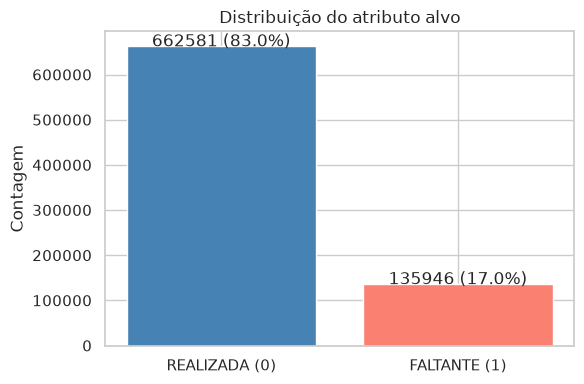

In [7]:
## Distribuição do atributo alvo
fig, ax = plt.subplots(figsize=(6, 4))
counts = df['situacaoagenda'].value_counts()
ax.bar(['REALIZADA (0)', 'FALTANTE (1)'], counts.values, color=['steelblue', 'salmon'])
ax.set_title("Distribuição do atributo alvo")
ax.set_ylabel("Contagem")
for i, v in enumerate(counts.values):
    ax.text(i, v + 20, f'{v} ({v/len(df)*100:.1f}%)', ha='center')
plt.tight_layout()
plt.show()

## Parte 1: Transformação de Dados

### 1.1 Divisão treino/teste

In [10]:
# Divisão treino/teste estratificada
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"Treino: {X_train_raw.shape[0]} amostras | Teste: {X_test_raw.shape[0]} amostras")
print(f"Distribuição no treino:\n{y_train.value_counts(normalize=True).round(3)}")

Treino: 638821 amostras | Teste: 159706 amostras
Distribuição no treino:
situacaoagenda
1.0    0.83
0.0    0.17
Name: proportion, dtype: float64


## 1.2 Análise exploratória das features numéricas

In [11]:
X_train_raw[num_cols].describe().round(2)

,diasfilaespera,idade,censo_favela_comunidade,censo_taxa_alfabetizacao,censo_renda_media_winsor,distancia_km,tempo_caminhando,distancia_km_trans_publico,tempo_desloc_trans_publico,quant_bus,baldiacoes
count,638821.00,638821.00,638821.00,638821.00,638821.00,638821.00,638821.00,638821.00,638821.00,638821.00,638821.00
mean,96.14,50.52,17.21,97.41,4011.65,9.20,129.40,11.36,39.12,1.48,0.52
std,160.16,22.76,22.94,1.51,2383.35,5.92,83.67,7.53,20.15,0.67,0.61
min,0.00,0.00,0.00,90.80,1426.23,0.00,0.00,0.00,0.00,0.00,0.00
25%,4.00,34.00,0.00,96.57,2124.24,5.04,70.00,6.13,25.93,1.00,0.00
50%,22.00,55.00,7.52,97.47,3223.68,8.11,113.63,9.96,38.07,1.00,0.00
75%,118.00,68.00,28.83,98.66,5002.69,12.88,182.10,15.74,51.48,2.00,1.00
max,2288.00,125.00,100.00,99.44,9824.08,504.94,6869.68,337.74,416.28,5.00,4.00


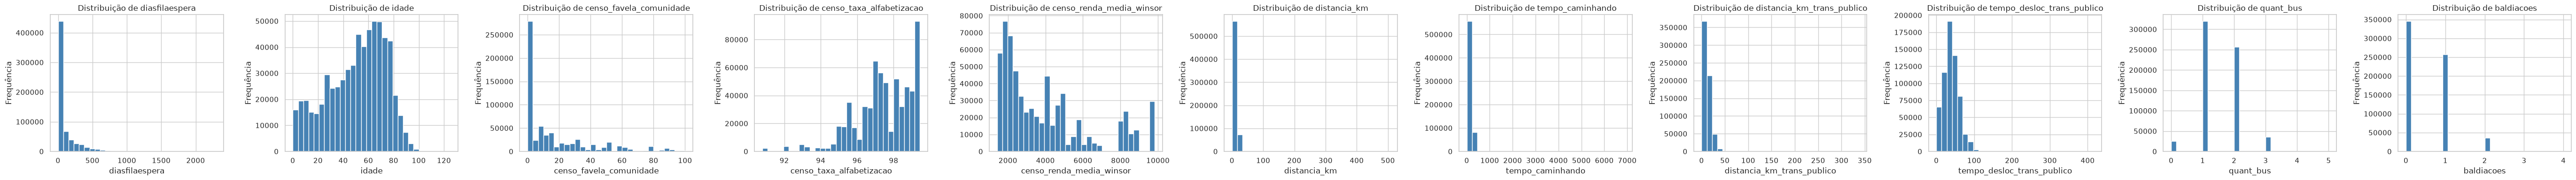

In [14]:
## Distribuições das variáveis numéricas no conjunto de treino
fig, axes = plt.subplots(1, len(num_cols), figsize=(5 * len(num_cols), 4))
for i, col in enumerate(num_cols):
    axes[i].hist(X_train_raw[col].dropna(), bins=30, color='steelblue', edgecolor='white')
    axes[i].set_title(f'Distribuição de {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequência')
plt.tight_layout()
plt.show()

## Parte 2: Imputação de Valores Ausentes

### 2.1 Diagnóstico de valores ausentes

In [16]:
## Verificar valores ausentes no conjunto de treino
missing = X_train_raw.isnull().sum()
missing_pct = (missing / len(X_train_raw) * 100).round(2)
missing_df = pd.DataFrame({'Ausentes': missing, 'Percentual (%)': missing_pct})
missing_df = missing_df[missing_df['Ausentes'] > 0].sort_values('Percentual (%)', ascending=False)
print("Colunas com valores ausentes no conjunto de treino:")
print(missing_df)

Colunas com valores ausentes no conjunto de treino:
              Ausentes  Percentual (%)
corregulador        86            0.01


### 2.2 Estratégias de imputação

Como o dado com valores ausentes é o corregulador que é categórico, iremos utilizar a estratégia da moda

In [19]:
imp_cat = ('imputer', SimpleImputer(strategy='most_frequent'))

## Parte 3: Tratamento de Outliers

In [20]:
## Detecção de outliers usando o método IQR nas variáveis numéricas do treino

def detect_outliers_iqr(df, cols):
    """Retorna DataFrame com informações sobre outliers em cada coluna numérica."""
    results = []
    for col in cols:
        serie = df[col].dropna()
        Q1 = serie.quantile(0.25)
        Q3 = serie.quantile(0.75)
        IQR = Q3 - Q1
        lb = Q1 - 1.2 * IQR
        ub = Q3 + 1.2 * IQR
        n_outliers = ((serie < lb) | (serie > ub)).sum()
        results.append({
            'Coluna': col,
            'Q1': round(Q1, 2),
            'Q3': round(Q3, 2),
            'IQR': round(IQR, 2),
            'Limite inferior': round(lb, 2),
            'Limite superior': round(ub, 2),
            'N outliers': n_outliers,
            '% outliers': round(n_outliers / len(serie) * 100, 2)
        })
    return pd.DataFrame(results).set_index('Coluna')

outlier_summary = detect_outliers_iqr(X_train_raw, num_cols)
print("Resumo de outliers por variável numérica (conjunto de treino):")
outlier_summary

Resumo de outliers por variável numérica (conjunto de treino):


,Q1,Q3,IQR,Limite inferior,Limite superior,N outliers,% outliers
Coluna,,,,,,,
diasfilaespera,4.00,118.00,114.00,-132.80,254.80,83353,13.05
idade,34.00,68.00,34.00,-6.80,108.80,4,0.00
censo_favela_comunidade,0.00,28.83,28.83,-34.60,63.43,35981,5.63
censo_taxa_alfabetizacao,96.57,98.66,2.09,94.07,101.16,16829,2.63
censo_renda_media_winsor,2124.24,5002.69,2878.45,-1329.90,8456.82,52731,8.25
distancia_km,5.04,12.88,7.84,-4.36,22.28,13822,2.16
tempo_caminhando,70.00,182.10,112.10,-64.52,316.62,14042,2.20
distancia_km_trans_publico,6.13,15.74,9.61,-5.40,27.27,22278,3.49
tempo_desloc_trans_publico,25.93,51.48,25.55,-4.73,82.14,19654,3.08


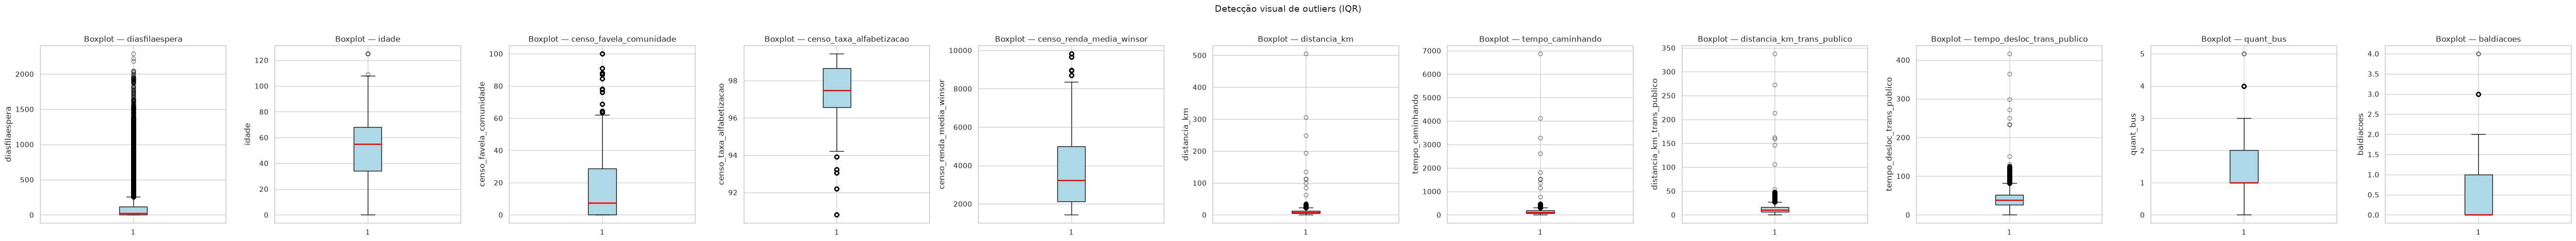

In [21]:
## Visualização dos outliers com boxplots
fig, axes = plt.subplots(1, len(num_cols), figsize=(5 * len(num_cols), 5))
for i, col in enumerate(num_cols):
    axes[i].boxplot(X_train_raw[col].dropna(), vert=True, patch_artist=True,
                    whis=1.2,#threshold usando no método IQR
                    boxprops=dict(facecolor='lightblue'),
                    medianprops=dict(color='red', linewidth=2),
                    flierprops=dict(marker='o', color='orange', alpha=0.5))
    axes[i].set_title(f'Boxplot — {col}')
    axes[i].set_ylabel(col)
plt.suptitle('Detecção visual de outliers (IQR)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [25]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [24]:
# Pré-processador BASE (sem escalonamento) — usado para métodos de seleção de atributos
def make_base_preprocessor():
    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median'))
    ])
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(drop='if_binary', sparse_output=False, handle_unknown='ignore'))
    ])
    return ColumnTransformer([
        ('numerical', num_pipe, num_cols),
        ('categorical', cat_pipe, cat_cols)
    ])

# Pré-processador COM StandardScaler — necessário para PCA
def make_scaled_preprocessor():
    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(drop='if_binary', sparse_output=False, handle_unknown='ignore'))
    ])
    return ColumnTransformer([
        ('numerical', num_pipe, num_cols),
        ('categorical', cat_pipe, cat_cols)
    ])

In [ ]:
## Configuração 1: Sem re-amostragem
pipeline_baseline = Pipeline([
    ('data_transform', make_base_preprocessor()),
    ('classifier', KNeighborsClassifier(n_neighbors=11))
])

In [ ]:
scores_baseline = cross_val_score(pipeline_baseline, X_train_raw, y_train,
                                   scoring='f1', cv=cv, n_jobs=-1)

In [31]:
## Configuração 2: SMOTE (oversampling)
pipe_smote = ImbPipeline(steps=[
    ('data_transform', make_scaled_preprocessor()),
    ('smote', SMOTE(random_state=SEED)),
    ('classifier', KNeighborsClassifier(n_neighbors=11))
])

In [ ]:
scores_smote = cross_val_score(pipe_nosampling, X_train_raw, y_train,
                                    scoring='f1', cv=cv, n_jobs=-1)

In [ ]:
## Parte 5: Avaliação Final no Conjunto de Teste

## Avaliação final — melhor pipeline no conjunto de teste
# Substitua 'pipe_smote' pelo pipeline com melhor F1 médio na CV

best_pipeline = pipeline_baseline # <-- ajuste conforme os resultados obtidos

best_pipeline.fit(X_train_raw, y_train)
y_pred = best_pipeline.predict(X_test_raw)

print("=== Relatório de Classificação — Conjunto de Teste ===")
print(classification_report(y_test, y_pred, target_names=['REALIZADA', 'FALTANTE']))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
                                         display_labels=['REALIZADA', 'FALTANTE'],
                                         cmap='Blues', ax=ax)
ax.set_title('Matriz de Confusão — Conjunto de Teste')
plt.tight_layout()
plt.show()